In [37]:
import os, sys
import numpy as np
import pickle
import uproot
import glob
import pandas as pd
from tqdm import tqdm
import json
import ROOT as rt
import fnmatch

## user define
sys.path.append('.')
sys.path.append('./Utils')
from Plotter import HistStack

from beeps import *

# Set config

In [38]:
# ERA="ee17"
# ERA="ee16pre"
# # ERA="mm18"
# ERA="em18"
# # DATE = '20230129_17_eleffmva'
# DATE = '20230301_18'
# # DATE = '20230130_18_dyhighworctight'
# # INPUTDIR = "/eos/user/h/hkwon/Run2/20230130_18_dyhighworctight/mm/"
# INPUTDIR = "/eos/user/h/hkwon/Run2/20230301_18/em/"
import sys
ERA = sys.argv[1]
DATE = sys.argv[2]
INPUTDIR = sys.argv[3]

DUMP_PKL = True
DRAW_SR = True
RUN_SIDEBAND_MET = True
RUN_SIDEBAND_MASS = True
RUN_SIDEBAND_PT = True
DUMP_SIDEBAND_MET_PKL = True
DUMP_SIDEBAND_MASS_PKL = True
DUMP_SIDEBAND_PT_PKL = True
RUN_BTAG = False
EXPORT_VARIABLE = False

# # for dev
# ERA="ee17"
# DATE = '20230502pdf_17'
# INPUTDIR = "/eos/user/h/hkwon/Run2/"+DATE+"/ee/"


# Get input

In [39]:
lumi_all={
    "ee16pre":19520,
    "ee16post":16810,
    "ee17":41480,
    "ee18":59830,
    "mm16pre":19520,
    "mm16post":16810,
    "mm17":41480,
    "mm18":59830,    
#     "mm18":14000,    
    "em16pre":19520,
    "em16post":16810,
    "em17":41480,
    "em18":59830     
}

data_evts = {
    "ee16pre":652566543,
    "ee16post":287977113,
    "ee17":460041183,
    "ee18":1326465857,
    "mm16pre":458655573,
    "mm16post":327037312,
    "mm17":739073837,
#     "mm18":944842550,  #949352777 
    "mm18":949352777,  #949352777 
    "em16pre":1111222116,
    "em16post":615014425,
    "em17":1199115020,
#     "em18":2271308407   #2281001366  
    "em18":2281001366   #2281001366  
}

lumi=lumi_all[ERA]
print(ERA, lumi)

channel = ERA.replace("16pre", "")
channel = channel.replace("16post", "")
channel = channel.replace("17", "")
channel = channel.replace("18", "")

def get_df(root_file_name, unneccesary_columns):
    f = uproot.open(root_file_name)
    df = uproot.open(root_file_name)["Events_"+channel].arrays(library="pd")
    df_met_u = uproot.open(root_file_name)["Events_"+channel+"_met_u"].arrays(library="pd")
    df_met_d = uproot.open(root_file_name)["Events_"+channel+"_met_d"].arrays(library="pd")    
#     df_scale_u = uproot.open(root_file_name)["Events_"+channel+"_scale_u"].arrays(library="pd")
#     df_scale_d = uproot.open(root_file_name)["Events_"+channel+"_scale_d"].arrays(library="pd")
    info = uproot.open(root_file_name)["Info_"+channel].arrays(library="pd")
#     return sum(info["sumweight"]), df.drop(unneccesary_columns, axis=1), df_met_u.drop(unneccesary_columns, axis=1), df_met_d.drop(unneccesary_columns, axis=1), df_scale_u.drop(unneccesary_columns, axis=1), df_scale_d.drop(unneccesary_columns, axis=1)
    return sum(info["sumweight"]), df.drop(unneccesary_columns, axis=1), df_met_u.drop(unneccesary_columns, axis=1), df_met_d.drop(unneccesary_columns, axis=1)

unneccesary_columns = []
dic_input = {
    "ee16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/ee/",
    "mm16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/mm/",
    "em16pre": "/eos/user/h/hkwon/Run2/"+DATE+"_16pre/em/",
    "ee16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/ee/",
    "mm16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/mm/",
    "em16post": "/eos/user/h/hkwon/Run2/"+DATE+"_16post/em/",
    "ee17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/ee/",
    "mm17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/mm/",
    "em17": "/eos/user/h/hkwon/Run2/"+DATE+"_17/em/",
    "ee18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/ee/",
    "mm18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/mm/",    
    "em18": "/eos/user/h/hkwon/Run2/"+DATE+"_18/em/"        
#     "em18": "/eos/user/h/hkwon/Run2/20221120_18/em/"        
}
# input_dir = dic_input[ERA]
input_dir = INPUTDIR
f = []
for (dirpath, dirnames, filenames) in os.walk(input_dir):
    f.extend(filenames)
    break

dic_tup={}
for file in tqdm(f):
    # file naming: flatNtuple_Preselect_WZ1.root, flatNtuple_Preselect_Zp-3700_CH-1345.root
    if not "flatNtuple" in file:
        continue
#     if channel=="mm" and (fnmatch.fnmatch(file, '*E*Run*') or fnmatch.fnmatch(file, '*M*RunB*') or fnmatch.fnmatch(file, '*M*RunC*') or fnmatch.fnmatch(file, '*M*RunD*')): #temp
    if channel=="mm" and fnmatch.fnmatch(file, '*E*Run*'): #temp
        continue
    if channel=="ee" and fnmatch.fnmatch(file, '*M*Run*'):
        continue
#     if channel=="em" and fnmatch.fnmatch(file, '*E*Run*'):
#         continue  

    if "Zp" in file:
        sample=file.split('_')[2]+"_"+file.split('_')[3]
    else:
        sample=file.split('_')[2]
    sample=sample.rstrip('.root')
    try:
        print(sample)
        dic_tup[sample]=get_df(input_dir+file, unneccesary_columns)   
    except:
        print(sample)
        beep()        
        if "Run" in sample: # check file corrupt
            raise    
# dic_tup

ee17 41480


  0%|          | 0/217 [00:00<?, ?it/s]

DY0


  0%|          | 1/217 [00:00<02:45,  1.31it/s]

DY1


...

 99%|█████████▉| 215/217 [01:53<00:01,  1.48it/s]

Zp-4100_CH-595


100%|█████████▉| 216/217 [01:54<00:00,  1.49it/s]

Zp-4100_CH-845


100%|██████████| 217/217 [01:55<00:00,  1.88it/s]


In [40]:
beep_ok()

In [41]:
# for key in dic_tup:
#     print(key)

In [42]:
# get x-sec
dic_xsec={}
with open('config/CrossSection.json') as json_file:
    data = json.load(json_file)
    dic_xsec=data
print(dic_xsec)

{'Data': 1, 'DY': 6077.22, 'DY500To700': 0.2558, 'DY700To800': 0.04023, 'DY800To1000': 0.03406, 'DY1000To1500': 0.01828, 'DY1500To2000': 0.002367, 'DY2000To3000': 0.0005409, 'TT': 88.29, 'TTUp': 88.29, 'TTDown': 88.29, 'TThdampUp': 88.29, 'TThdampDown': 88.29, 'TTSemi': 365.34, 'TTZ': 0.2432, 'top': 34.91, 'antitop': 34.91, 'WW': 10.48, 'WZ': 5.052, 'ZZ': 0.6008, 'Zp-1700_CH-345': 0.03523, 'Zp-1700_CH-595': 0.03523, 'Zp-1700_CH-845': 0.03523, 'Zp-2100_CH-345': 0.01198, 'Zp-2100_CH-595': 0.01198, 'Zp-2100_CH-845': 0.01198, 'Zp-2500_CH-345': 0.004396, 'Zp-2500_CH-595': 0.004396, 'Zp-2500_CH-845': 0.004396, 'Zp-2500_CH-1095': 0.004396, 'Zp-2900_CH-345': 0.001768, 'Zp-2900_CH-595': 0.001768, 'Zp-2900_CH-845': 0.001768, 'Zp-2900_CH-1095': 0.001768, 'Zp-2900_CH-1345': 0.001768, 'Zp-3300_CH-345': 0.000729, 'Zp-3300_CH-595': 0.000729, 'Zp-3300_CH-845': 0.000729, 'Zp-3300_CH-1095': 0.000729, 'Zp-3300_CH-1345': 0.000729, 'Zp-3300_CH-1595': 0.000729, 'Zp-3700_CH-345': 0.00031, 'Zp-3700_CH-595': 0

In [43]:
Data_concat, TT_concat, TTSemi_concat, TTZ_concat, DY_concat, top_concat, antitop_concat, WW_concat, WZ_concat, ZZ_concat = ([] for i in range(10))
Data_concat_met_u, TT_concat_met_u, TTSemi_concat_met_u, TTZ_concat_met_u, DY_concat_met_u, top_concat_met_u, antitop_concat_met_u, WW_concat_met_u, WZ_concat_met_u, ZZ_concat_met_u = ([] for i in range(10))
Data_concat_met_d, TT_concat_met_d, TTSemi_concat_met_d, TTZ_concat_met_d, DY_concat_met_d, top_concat_met_d, antitop_concat_met_d, WW_concat_met_d, WZ_concat_met_d, ZZ_concat_met_d = ([] for i in range(10))
Data_concat_scale_u, TT_concat_scale_u, TTSemi_concat_scale_u, TTZ_concat_scale_u, DY_concat_scale_u, top_concat_scale_u, antitop_concat_scale_u, WW_concat_scale_u, WZ_concat_scale_u, ZZ_concat_scale_u = ([] for i in range(10))
Data_concat_scale_d, TT_concat_scale_d, TTSemi_concat_scale_d, TTZ_concat_scale_d, DY_concat_scale_d, top_concat_scale_d, antitop_concat_scale_d, WW_concat_scale_d, WZ_concat_scale_d, ZZ_concat_scale_d = ([] for i in range(10))
TTUp_concat, TTDown_concat, TThdampUp_concat, TThdampDown_concat = ([] for i in range(4)) 
TTUp_concat_met_u, TTDown_concat_met_u, TThdampUp_concat_met_u, TThdampDown_concat_met_u = ([] for i in range(4)) 
TTUp_concat_met_d, TTDown_concat_met_d, TThdampUp_concat_met_d, TThdampDown_concat_met_d = ([] for i in range(4)) 

Data_nevts, TT_nevts, TTSemi_nevts, TTZ_nevts, DY_nevts, top_nevts, antitop_nevts, WW_nevts, WZ_nevts, ZZ_nevts = ([] for i in range(10))
TTUp_nevts, TTDown_nevts, TThdampUp_nevts, TThdampDown_nevts = ([] for i in range(4))

merged_dic_df={}
for key in dic_tup:
    if fnmatch.fnmatch(key, 'DY?') or fnmatch.fnmatch(key, 'DY1?'):
#         print(key)
#         print(dic_tup[key][0])
        DY_concat.append(dic_tup[key][1])
        DY_concat_met_u.append(dic_tup[key][2])
        DY_concat_met_d.append(dic_tup[key][3])        
#         DY_concat_scale_u.append(dic_tup[key][4])
#         DY_concat_scale_d.append(dic_tup[key][5])
        DY_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, 'TT?') or fnmatch.fnmatch(key, 'TT1?'):
#         print("TT", key)
#         print(dic_tup[key][0])
        TT_concat.append(dic_tup[key][1])
        TT_concat_met_u.append(dic_tup[key][2])
        TT_concat_met_d.append(dic_tup[key][3])
#         TT_concat_scale_u.append(dic_tup[key][4])
#         TT_concat_scale_d.append(dic_tup[key][5])
        TT_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TThdampUp?') or fnmatch.fnmatch(key, 'TThdampUp1?'):
#         print(key)
#         print(dic_tup[key][0])
        TThdampUp_concat.append(dic_tup[key][1])
        TThdampUp_concat_met_u.append(dic_tup[key][2])
        TThdampUp_concat_met_d.append(dic_tup[key][3])
        TThdampUp_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TThdampDown?') or fnmatch.fnmatch(key, 'TThdampDown1?'):
#         print(key)
#         print(dic_tup[key][0])
        TThdampDown_concat.append(dic_tup[key][1])
        TThdampDown_concat_met_u.append(dic_tup[key][2])
        TThdampDown_concat_met_d.append(dic_tup[key][3])
        TThdampDown_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTUp?') or fnmatch.fnmatch(key, 'TTUp1?'):
#         print(key)
#         print(dic_tup[key][0])
        TTUp_concat.append(dic_tup[key][1])
        TTUp_concat_met_u.append(dic_tup[key][2])
        TTUp_concat_met_d.append(dic_tup[key][3])
        TTUp_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTDown?') or fnmatch.fnmatch(key, 'TTDown1?'):
#         print(key)
#         print(dic_tup[key][0])
        TTDown_concat.append(dic_tup[key][1])
        TTDown_concat_met_u.append(dic_tup[key][2])
        TTDown_concat_met_d.append(dic_tup[key][3])
        TTDown_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTSemi*'):
#         print(key)
#         print(dic_tup[key][0])
        TTSemi_concat.append(dic_tup[key][1])
        TTSemi_concat_met_u.append(dic_tup[key][2])
        TTSemi_concat_met_d.append(dic_tup[key][3])
#         TTSemi_concat_scale_u.append(dic_tup[key][4])
#         TTSemi_concat_scale_d.append(dic_tup[key][5])
        TTSemi_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TTZ*'):
#         print(key)
#         print(dic_tup[key][0])
        TTZ_concat.append(dic_tup[key][1])
        TTZ_concat_met_u.append(dic_tup[key][2])
        TTZ_concat_met_d.append(dic_tup[key][3])
#         TTZ_concat_scale_u.append(dic_tup[key][4])
#         TTZ_concat_scale_d.append(dic_tup[key][5])
        TTZ_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'TW?'):
#         print(key)
#         print(dic_tup[key][0])
        top_concat.append(dic_tup[key][1])
        top_concat_met_u.append(dic_tup[key][2])
        top_concat_met_d.append(dic_tup[key][3])
#         top_concat_scale_u.append(dic_tup[key][4])
#         top_concat_scale_d.append(dic_tup[key][5])
        top_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, 'TWa?'):
#         print(key)
#         print(dic_tup[key][0])
        antitop_concat.append(dic_tup[key][1])
        antitop_concat_met_u.append(dic_tup[key][2])
        antitop_concat_met_d.append(dic_tup[key][3])
#         antitop_concat_scale_u.append(dic_tup[key][4])
#         antitop_concat_scale_d.append(dic_tup[key][5])
        antitop_nevts.append(dic_tup[key][0]) 
    if fnmatch.fnmatch(key, 'WW*'):
        WW_concat.append(dic_tup[key][1])
        WW_concat_met_u.append(dic_tup[key][2])
        WW_concat_met_d.append(dic_tup[key][3])
#         WW_concat_scale_u.append(dic_tup[key][4])
#         WW_concat_scale_d.append(dic_tup[key][5])
        WW_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, 'WZ*'):
        WZ_concat.append(dic_tup[key][1])
        WZ_concat_met_u.append(dic_tup[key][2])
        WZ_concat_met_d.append(dic_tup[key][3])
#         WZ_concat_scale_u.append(dic_tup[key][4])
#         WZ_concat_scale_d.append(dic_tup[key][5])
        WZ_nevts.append(dic_tup[key][0])
    if fnmatch.fnmatch(key, 'ZZ*'):
        ZZ_concat.append(dic_tup[key][1])
        ZZ_concat_met_u.append(dic_tup[key][2])
        ZZ_concat_met_d.append(dic_tup[key][3])
#         ZZ_concat_scale_u.append(dic_tup[key][4])
#         ZZ_concat_scale_d.append(dic_tup[key][5])
        ZZ_nevts.append(dic_tup[key][0])        
    if fnmatch.fnmatch(key, '*Run*'):
        Data_concat.append(dic_tup[key][1])
        Data_concat_met_u.append(dic_tup[key][2])
        Data_concat_met_d.append(dic_tup[key][3])
#         Data_concat_scale_u.append(dic_tup[key][4])
#         Data_concat_scale_d.append(dic_tup[key][5])
        Data_nevts.append(dic_tup[key][0]) 
    if fnmatch.fnmatch(key, 'Zp*'): 
        merged_dic_df[key]=dic_tup[key]
    if fnmatch.fnmatch(key, 'DY*To*'): 
        merged_dic_df[key]=dic_tup[key]
#         print("high", key)

In [44]:
# free memory 
dic_tup.clear()

In [45]:
totalinput = """
######################################################
####   Total input number of events (sumweight)   ####
######################################################
"""

print(totalinput)
if TT_concat:
#     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
    merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d)
    tmp = "TT: "+str(sum(TT_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if TThdampUp_concat:
#     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
    merged_dic_df['TThdampUp']=sum(TThdampUp_nevts), pd.concat(TThdampUp_concat), pd.concat(TThdampUp_concat_met_u), pd.concat(TThdampUp_concat_met_d)
    tmp = "TThdampUp: "+str(sum(TThdampUp_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if TThdampDown_concat:
#     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
    merged_dic_df['TThdampDown']=sum(TThdampDown_nevts), pd.concat(TThdampDown_concat), pd.concat(TThdampDown_concat_met_u), pd.concat(TThdampDown_concat_met_d)
    tmp = "TThdampDown: "+str(sum(TThdampDown_nevts))
    print(tmp)
    totalinput+=tmp+"\n"    
if TTUp_concat:
#     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
    merged_dic_df['TTUp']=sum(TTUp_nevts), pd.concat(TTUp_concat), pd.concat(TTUp_concat_met_u), pd.concat(TTUp_concat_met_d)
    tmp = "TTUp: "+str(sum(TTUp_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if TTDown_concat:
#     merged_dic_df['TT']=sum(TT_nevts), pd.concat(TT_concat), pd.concat(TT_concat_met_u), pd.concat(TT_concat_met_d), pd.concat(TT_concat_scale_u), pd.concat(TT_concat_scale_d)
    merged_dic_df['TTDown']=sum(TTDown_nevts), pd.concat(TTDown_concat), pd.concat(TTDown_concat_met_u), pd.concat(TTDown_concat_met_d)
    tmp = "TTDown: "+str(sum(TTDown_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if TTSemi_concat:
#     merged_dic_df['TTSemi']=sum(TTSemi_nevts), pd.concat(TTSemi_concat), pd.concat(TTSemi_concat_met_u), pd.concat(TTSemi_concat_met_d), pd.concat(TTSemi_concat_scale_u), pd.concat(TTSemi_concat_scale_d)
    merged_dic_df['TTSemi']=sum(TTSemi_nevts), pd.concat(TTSemi_concat), pd.concat(TTSemi_concat_met_u), pd.concat(TTSemi_concat_met_d)
    tmp = "TTSemi: "+str(sum(TTSemi_nevts))
    print(tmp)
    totalinput+=tmp+"\n"    
if TTZ_concat:
#     merged_dic_df['TTZ']=sum(TTZ_nevts), pd.concat(TTZ_concat), pd.concat(TTZ_concat_met_u), pd.concat(TTZ_concat_met_d), pd.concat(TTZ_concat_scale_u), pd.concat(TTZ_concat_scale_d)
    merged_dic_df['TTZ']=sum(TTZ_nevts), pd.concat(TTZ_concat), pd.concat(TTZ_concat_met_u), pd.concat(TTZ_concat_met_d)
    tmp = "TTZ: "+str(sum(TTZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n"
if DY_concat:
#     merged_dic_df['DY']=sum(DY_nevts), pd.concat(DY_concat), pd.concat(DY_concat_met_u), pd.concat(DY_concat_met_d), pd.concat(DY_concat_scale_u), pd.concat(DY_concat_scale_d)
    merged_dic_df['DY']=sum(DY_nevts), pd.concat(DY_concat), pd.concat(DY_concat_met_u), pd.concat(DY_concat_met_d)
    tmp = "DY: "+str(sum(DY_nevts))
    print(tmp)
    totalinput+=tmp+"\n"    
if top_concat:
    df=pd.concat(top_concat)
#     merged_dic_df['top']=sum(top_nevts), pd.concat(top_concat), pd.concat(top_concat_met_u), pd.concat(top_concat_met_d), pd.concat(top_concat_scale_u), pd.concat(top_concat_scale_d)
    merged_dic_df['top']=sum(top_nevts), pd.concat(top_concat), pd.concat(top_concat_met_u), pd.concat(top_concat_met_d)
    tmp = "top: "+str(sum(top_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if antitop_concat:
    df=pd.concat(antitop_concat)
#     merged_dic_df['antitop']=sum(antitop_nevts), pd.concat(antitop_concat), pd.concat(antitop_concat_met_u), pd.concat(antitop_concat_met_d), pd.concat(antitop_concat_scale_u), pd.concat(antitop_concat_scale_d)
    merged_dic_df['antitop']=sum(antitop_nevts), pd.concat(antitop_concat), pd.concat(antitop_concat_met_u), pd.concat(antitop_concat_met_d)
    tmp = "antitop: "+str(sum(antitop_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if ZZ_concat:
    df=pd.concat(ZZ_concat)
#     merged_dic_df['ZZ']=sum(ZZ_nevts), pd.concat(ZZ_concat), pd.concat(ZZ_concat_met_u), pd.concat(ZZ_concat_met_d), pd.concat(ZZ_concat_scale_u), pd.concat(ZZ_concat_scale_d)
    merged_dic_df['ZZ']=sum(ZZ_nevts), pd.concat(ZZ_concat), pd.concat(ZZ_concat_met_u), pd.concat(ZZ_concat_met_d)
    tmp = "ZZ: "+str(sum(ZZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if WZ_concat:
    df=pd.concat(WZ_concat)
#     merged_dic_df['WZ']=sum(WZ_nevts), pd.concat(WZ_concat), pd.concat(WZ_concat_met_u), pd.concat(WZ_concat_met_d), pd.concat(WZ_concat_scale_u), pd.concat(WZ_concat_scale_d)
    merged_dic_df['WZ']=sum(WZ_nevts), pd.concat(WZ_concat), pd.concat(WZ_concat_met_u), pd.concat(WZ_concat_met_d)
    tmp = "WZ: "+str(sum(WZ_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if WW_concat:
    df=pd.concat(WW_concat)
#     merged_dic_df['WW']=sum(WW_nevts), pd.concat(WW_concat), pd.concat(WW_concat_met_u), pd.concat(WW_concat_met_d), pd.concat(WW_concat_scale_u), pd.concat(WW_concat_scale_d)
    merged_dic_df['WW']=sum(WW_nevts), pd.concat(WW_concat), pd.concat(WW_concat_met_u), pd.concat(WW_concat_met_d)
    tmp = "WW: "+str(sum(WW_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
if Data_concat:
#     merged_dic_df['Data']=sum(Data_nevts), pd.concat(Data_concat), pd.concat(Data_concat_met_u), pd.concat(Data_concat_met_d), pd.concat(Data_concat_scale_u), pd.concat(Data_concat_scale_d)
    merged_dic_df['Data']=sum(Data_nevts), pd.concat(Data_concat), pd.concat(Data_concat_met_u), pd.concat(Data_concat_met_d)
    tmp = "Data: "+str(sum(Data_nevts))
    print(tmp)
    totalinput+=tmp+"\n" 
# merged_dic_df["Zp-2500"]=dic_tup["Zp-2500"][0], dic_tup["Zp-2500"][1] 



######################################################
####   Total input number of events (sumweight)   ####
######################################################

TT: 105859990
TThdampUp: 39703672
TThdampDown: 38731490
TTUp: 42044778
TTDown: 38967610
TTSemi: 343257666
TTZ: 6911466
DY: 131545008
top: 5648712
antitop: 5673702
ZZ: 40753260
WZ: 24963396
WW: 7071358
Data: 460041183


In [46]:
os.system("mkdir -p "+DATE+"/Presel/"+ERA)
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'w') as f:
    f.write(totalinput)

In [47]:
print("expected:", data_evts[ERA], ", while: ", sum(Data_nevts))

# try:
#    if data_evts[ERA]!=sum(Data_nevts):
#        raise ValueError('Data events missing!')
# except (ValueError, IndexError):
#    beep()
#    print("expected:", data_evts[ERA], ", while: ", sum(Data_nevts)) 
#    raise

expected: 460041183 , while:  460041183


In [48]:
# # temp!!
for key in merged_dic_df:
    df = merged_dic_df[key][1]
    df_met_u = merged_dic_df[key][2]
    df_met_d = merged_dic_df[key][3]    
#     df_scale_u = merged_dic_df[key][4]
#     df_scale_d = merged_dic_df[key][5]
#     print(df[df.isin([np.inf, -np.inf]).any(1)])
    if df.isnull().values.any():
        print("Warning, nan in",key)
        i = df[df.isin([np.nan, np.inf, -np.inf]).any(1)].index
        print(i)
        df_new = df.drop(i)
        df_met_u_new = df_met_u.drop(i)
        df_met_d_new = df_met_d.drop(i)
#         print(df_new.isnull().values.any())
        #workaround for tuple assignment
#         merged_dic_df[key] = merged_dic_df[key][0], df_new, df_met_u_new, df_met_d_new, df_scale_u, df_scale_d
        merged_dic_df[key] = merged_dic_df[key][0], df_new, df_met_u_new, df_met_d_new
        


In [49]:
sys = ["puweight_pre", "l1prefiring_pre", 'effSF_pre', 'topSF_pre', 'genweight_pre', 'trigSF_pre']
# sys = ["puweight_pre", "l1prefiring_pre", 'effSF_pre', 'topSF_pre', 'genweight_pre']
eventweights = """
####################################################
####       event weights (normalization)        ####
####################################################
"""

def get_dic_with_weight(merged_dic_df):
    dic_df={}
    dic_df_met_u={}
    dic_df_met_d={}
    dic_df_scale_u={}
    dic_df_scale_d={}
    for key, vs in merged_dic_df.items():
        print(key) 
        if vs[0]==0:
            print("missing: ", key, "!, continue without it")
            continue
        if "Data" in key:
            norm=1
        else:
            if fnmatch.fnmatch(key, '*DY*To*'):
                key = key[:len(key)-1]
            norm=lumi*dic_xsec[key]/vs[0]
        print(key, ":", norm)
        global eventweights
        eventweights+=key+":"+str(norm)+"\n"
#         print(eventweights)
        dic_df[key]=vs[1]
        dic_df_met_u[key] = vs[2]
        dic_df_met_d[key]=vs[3]
#         dic_df_scale_u[key] = vs[4]
#         dic_df_scale_d[key]=vs[5]
        dic_df[key]["weight"] = vs[1]["genweight_pre"]*norm
        dic_df_met_u[key]["weightmetUp"] = vs[1]["genweight_pre"]*norm
        dic_df_met_d[key]["weightmetDown"] = vs[1]["genweight_pre"]*norm
#         dic_df_scale_u[key]["weightscaleUp"] = vs[4]["totweight"].copy(deep=True)
#         dic_df_scale_d[key]["weightscaleDown"] =vs[5]["totweight"].copy(deep=True)
        dic_df[key]["wopu"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["wol1"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["woeff"] = vs[1]["genweight_pre"]*norm
        dic_df[key]["wotop"] = vs[1]["genweight_pre"]*norm       
        dic_df[key]["wobsf"] = vs[1]["genweight_pre"]*norm       
      
        for s in sys:
            if s=="genweight_pre":
                continue
            dic_df[key]["weight"] *= vs[1][s]
            dic_df[key]["weighthdampUp"] = dic_df[key]["weight"].copy(deep=True)
            dic_df[key]["weighthdampDown"] = dic_df[key]["weight"].copy(deep=True)
            dic_df[key]["weightPSUp"] = dic_df[key]["weight"].copy(deep=True)
            dic_df[key]["weightPSDown"] = dic_df[key]["weight"].copy(deep=True)
            dic_df_met_u[key]["weightmetUp"] *= vs[1][s]
            dic_df_met_d[key]["weightmetDown"] *= vs[1][s]
            # n-1 correction
            if s!="puweight_pre":
                dic_df[key]["wopu"] *= vs[1][s]
            if s!="l1prefiring_pre":
                dic_df[key]["wol1"] *= vs[1][s]
            if s!="effSF_pre":
                dic_df[key]["woeff"] *= vs[1][s]
#             if s!="topSF_pre":
            if not "top" in s:
                dic_df[key]["wotop"] *= vs[1][s]
            if s!="btagSF_pre":
                dic_df[key]["wobsf"] *= vs[1][s]
        #btag    
#         dic_df[key]["btag2"] = dic_df[key]["weight"].copy(deep=True)*vs[1]['btagSF2_pre'] 
#         dic_df[key]["btagSF"] = dic_df[key]["weight"].copy(deep=True)*vs[1]['btagSF_pre']
            
        # up, down    
        for s1 in sys:
            #if "top" in s1 or "eff" in s1:
            if "btag" in s1:
                continue
            s_u = s1.replace("_", "_u_")
            s_d = s1.replace("_", "_d_")
            if s1=="genweight_pre":
                dic_df[key]["weight"+s_u.replace('_u_pre', 'Up')] = dic_df[key]["weight"].copy(deep=True)*np.fabs(dic_df[key][s_u])
                dic_df[key]["weight"+s_d.replace('_d_pre', 'Down')] = dic_df[key]["weight"].copy(deep=True)*np.fabs(dic_df[key][s_d])
            else:
                dic_df[key]["weight"+s_u.replace('_u_pre', 'Up')] = dic_df[key]["weight"].copy(deep=True)/dic_df[key][s1]*dic_df[key][s_u]
                dic_df[key]["weight"+s_d.replace('_d_pre', 'Down')] = dic_df[key]["weight"].copy(deep=True)/dic_df[key][s1]*dic_df[key][s_d]             
#     return dic_df, dic_df_met_u, dic_df_met_d, dic_df_scale_u, dic_df_scale_d
    return dic_df, dic_df_met_u, dic_df_met_d

# dic_df, dic_df_met_u, dic_df_met_d, dic_df_scale_u, dic_df_scale_d = get_dic_with_weight(merged_dic_df)
dic_df, dic_df_met_u, dic_df_met_d = get_dic_with_weight(merged_dic_df)


DY1000To15000
DY1000To1500 : 0.006725273399735692
DY1500To20000
DY1500To2000 : 0.0008913829700309587
DY2000To30000
DY2000To3000 : 0.00019855513765608545
DY500To7000
DY500To700 : 0.0660359101064856
DY700To8000
DY700To800 : 0.014978640672124085
DY800To10000
DY800To1000 : 0.012300589428593817
Zp-1700_CH-345
Zp-1700_CH-345 : 0.009742269333333333
Zp-1700_CH-595
Zp-1700_CH-595 : 0.009742269333333333
Zp-1700_CH-845
Zp-1700_CH-845 : 0.009742269333333333
Zp-2100_CH-345
Zp-2100_CH-345 : 0.003312869333333333
Zp-2100_CH-595
Zp-2100_CH-595 : 0.003312869333333333
Zp-2100_CH-845
Zp-2100_CH-845 : 0.003312869333333333
Zp-2500_CH-345
Zp-2500_CH-345 : 0.0012156405333333333
Zp-2500_CH-595
Zp-2500_CH-595 : 0.0012156405333333333
Zp-2500_CH-845
Zp-2500_CH-845 : 0.0012156405333333333
Zp-2900_CH-1095
Zp-2900_CH-1095 : 0.0004889109333333333
Zp-2900_CH-1345
Zp-2900_CH-1345 : 0.0004889109333333333
Zp-2900_CH-345
Zp-2900_CH-345 : 0.0004889109333333333
Zp-2900_CH-595
Zp-2900_CH-595 : 0.0004889109333333333
Zp-2900_C

In [50]:
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'a') as f:
    f.write(eventweights)

# Preselection

In [51]:
weihtedevents = """
#############################################################
####   unweighted (weighted) #events after preselection  ####
#############################################################
"""
dic_df_raw={}
dic_df_met_u_tmp = {}
dic_df_met_d_tmp = {}
# dic_df_scale_u_tmp = {}
# dic_df_scale_d_tmp = {}
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and roccoMET_pre>100"
query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and PuppiMET_pre>100"
# query_str="mass_pre>100 and pt_lead_pre>500 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>660 and pt_trail_pre>40 and MET_pre>100"
# query_str="pt_lead_pre>80 and pt_trail_pre>40"
# query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
# query_str="mass_pre>60"


for key in dic_df:  
    dic_df_raw[key]=dic_df[key].query(query_str)
    dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
    dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)    
#     dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#     dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str)
    unweighted_nevt = dic_df_raw[key].shape[0]
    print(key, ":", unweighted_nevt, "(", sum(dic_df_raw[key]["weight"]), ")")
    print(key, "(met_u) :", dic_df_met_u_tmp[key].shape[0])
    print(key, "(met_d) :", dic_df_met_d_tmp[key].shape[0])
#     print(key, "(scale_u) :", dic_df_scale_u_tmp[key].shape[0])
#     print(key, "(scale_d) :", dic_df_scale_d_tmp[key].shape[0])    
#     print(key, "(scale_u) :", dic_df_scale_u[key].shape[0])
#     print(key, "(scale_d) :", dic_df_scale_d[key].shape[0])
    weihtedevents+=key+":"+str(unweighted_nevt)+"("+str(sum(dic_df_raw[key]["weight"]))+")\n"
#     print(key, ":", unweighted_nevt, "(", unweighted_nevt*lumi*dic_xsec[key]/merged_dic_df[key][0], ")")

nested_dic_df={}
nested_dic_df["raw"]=dic_df_raw
nested_dic_df["met_u"]=dic_df_met_u_tmp
nested_dic_df["met_d"]=dic_df_met_d_tmp
# nested_dic_df["scale_u"]=dic_df_scale_u_tmp
# nested_dic_df["scale_d"]=dic_df_scale_d_tmp

DY1000To1500 : 758 ( 2.3819180460149934 )
DY1000To1500 (met_u) : 819
DY1000To1500 (met_d) : 702
DY1500To2000 : 1059 ( 0.4519599310249645 )
DY1500To2000 (met_u) : 1106
DY1500To2000 (met_d) : 1007
DY2000To3000 : 1439 ( 0.13488323371760022 )
DY2000To3000 (met_u) : 1493
DY2000To3000 (met_d) : 1382
DY500To700 : 355 ( 9.299591494460289 )
DY500To700 (met_u) : 413
DY500To700 (met_d) : 329
DY700To800 : 419 ( 3.2739657324376314 )
DY700To800 (met_u) : 456
DY700To800 (met_d) : 384
DY800To1000 : 580 ( 3.125633630988303 )
DY800To1000 (met_u) : 646
DY800To1000 (met_d) : 545
Zp-1700_CH-345 : 8892 ( 79.45851432368465 )
Zp-1700_CH-345 (met_u) : 8917
Zp-1700_CH-345 (met_d) : 8866
Zp-1700_CH-595 : 11055 ( 98.87464724666849 )
Zp-1700_CH-595 (met_u) : 11067
Zp-1700_CH-595 (met_d) : 11033
Zp-1700_CH-845 : 12194 ( 109.58128594402889 )
Zp-1700_CH-845 (met_u) : 12192
Zp-1700_CH-845 (met_d) : 12188
Zp-2100_CH-345 : 10610 ( 32.418529776677495 )
Zp-2100_CH-345 (met_u) : 10622
Zp-2100_CH-345 (met_d) : 10574
Zp-2100

In [52]:
dic_df_raw["TT"]["topSF_pre"]

0         0.953900
3         0.978365
26        0.983895
29        0.975870
32        0.969140
            ...   
132858    1.010824
132859    0.973654
132863    0.954911
132872    0.985921
132879    1.010061
Name: topSF_pre, Length: 220575, dtype: float32

In [53]:
dic_df_raw["TThdampUp"]["topSF_pre"]

0        0.927010
5        0.979990
13       0.954088
16       0.944690
19       0.972971
           ...   
23908    0.884468
23909    0.945465
23919    0.963806
23933    0.956286
23943    0.951372
Name: topSF_pre, Length: 83562, dtype: float32

In [54]:
dic_df_raw["TTZ"]["topSF_pre"]

6         1.0
27        1.0
62        1.0
70        1.0
80        1.0
         ... 
124123    1.0
124137    1.0
124197    1.0
124199    1.0
124202    1.0
Name: topSF_pre, Length: 16831, dtype: float32

In [55]:
with open(DATE+"/Presel/"+ERA+'/Nevents.txt', 'a') as f:
    f.write(weihtedevents)

In [56]:
if DUMP_PKL:
    os.system("mkdir -p "+DATE+"/Presel/"+ERA)
    print("Dump pickle")
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

Dump pickle


# Draw

In [57]:
# draw
# get plot configuration
dic_variable={
#     "PuppiMET_pre": [14, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
# #     "MET_pre": [28, 0, 660, "p_{T}^{miss} [GeV]"],    
#     "mass_pre": [22, 100, 1000, "M_{ll} [GeV]"],
    "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
    "pt_trail_pre": [15, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#     "Zpt_pre": [25, 0, 500, "p_{T}(ll) [GeV]"],
#     "MT_pre": [27, 0, 550, "M_{T} [GeV]"],
#     "MT2_pre": [17, 0, 350, "M_{T2} [GeV]"],
#     "U_pre": [14, 0, 660, "U [GeV]"],
#     "JZB_pre": [14, 80, 660, "JZB"],
#     "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#     "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#     "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#     "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
# # #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
# # #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
# # #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
#     "eta_lead_pre": [15, -3, 3, "#eta(l_{lead})"],
#     "eta_trail_pre": [15, -3, 3, "#eta(l_{trail})"],
# # #     "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
# # #     "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#     "PuppiMET_phi_pre": [20, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],     
#     "nbjetflav_pre": [10, 0, 10, "N bjetflav"],     
#     "nbjet_pre": [10, 0, 10, "N bjet"],     
#     "njet_pre": [10, 0, 10, "N jet"],     
#     "njet_l_pre": [10, 0, 10, "N  l jet"],     
#     "njet_c_pre": [10, 0, 10, "N  c jet"],     
#     "njet_b_pre": [10, 0, 10, "N  b jet"],     
#     "btagSF_pre": [100, 0, 10, "SV dxy"],     
}
if "em" in ERA:
    dic_variable["pt_el_pre"] = [15, 20,  660, "p_{T}(e) [GeV]"]
    dic_variable["pt_mu_pre"] = [15, 20,  660, "p_{T}(#mu) [GeV]"]
print(dic_variable)
list_variables = [(key, dic_variable[key]) for key in dic_variable]
print(list_variables)

{'PuppiMET_pre': [14, 100, 660, 'Puppi p_{T}^{miss} [GeV]'], 'mass_pre': [22, 100, 1000, 'M_{ll} [GeV]'], 'pt_lead_pre': [15, 80, 660, 'p_{T}(l_{lead}) [GeV]'], 'pt_trail_pre': [15, 40, 520, 'p_{T}(l_{trail}) [GeV]'], 'Zpt_pre': [25, 0, 500, 'p_{T}(ll) [GeV]'], 'MT_pre': [27, 0, 550, 'M_{T} [GeV]'], 'MT2_pre': [17, 0, 350, 'M_{T2} [GeV]'], 'U_pre': [14, 0, 660, 'U [GeV]'], 'JZB_pre': [14, 80, 660, 'JZB'], 'dPhill_pre': [17, 0, 3.4, '#Delta#phi(l,l)'], 'dPhilMET_pre': [17, 0, 3.4, '#Delta#phi(l,p_{T}^{miss})'], 'dRll_pre': [30, 0, 6, '#DeltaR(l,l)'], 'dPhillMET_pre': [17, 0, 3.4, '#Delta#phi(ll,p_{T}^{miss})'], 'eta_lead_pre': [15, -3, 3, '#eta(l_{lead})'], 'eta_trail_pre': [15, -3, 3, '#eta(l_{trail})'], 'PuppiMET_phi_pre': [20, -4, 4, 'Puppi p_{T}^{miss} #phi(l_{trail})']}
[('PuppiMET_pre', [14, 100, 660, 'Puppi p_{T}^{miss} [GeV]']), ('mass_pre', [22, 100, 1000, 'M_{ll} [GeV]']), ('pt_lead_pre', [15, 80, 660, 'p_{T}(l_{lead}) [GeV]']), ('pt_trail_pre', [15, 40, 520, 'p_{T}(l_{trail})

In [58]:
SYS_LIST = ["puweight", "l1prefiring", "effSF", "topSF", "met", "trigSF", "hdamp", "PS"]
# SYS_LIST = ["hdamp", "PS"]

In [59]:
import math
# sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "met", "scale"]
# sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "met"]
# sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "met"]
sys_list = SYS_LIST
# sys_list = ["l1prefiring"]

def draw_with_systematics(dic_df_raw, dic_nested_shape_sys, sys_list, variable, r, region):
    """
        draw histograms with sys variations, return sys uncertainty dic
    """
    dic_sys = {}
    dic_sys_sqr = {}
    # nominal weight plot
    hist=HistStack(dic_df_raw, variable, 'weight', r[0], r[1], r[2], r[3])            
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/norm_"+query_str)     
    dic_yields = hist.get_yields_by_bin()
    bkg_norm = dic_yields['bkg']

    for s in sys_list:
        if "met" in s or "scale" in s: # fill later
            continue
        # up
        hist=HistStack(dic_df_raw, variable, 'weight'+s+'Up', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys[s+'Up'] = np.array(sysUp) - np.array(bkg_norm)
        # down
        hist=HistStack(dic_df_raw, variable, 'weight'+s+'Down', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systDown_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysDown = dic_yields['bkg']
        dic_sys[s+'Down'] = np.array(sysDown) - np.array(bkg_norm)
    if "el_pre" not in variable and "mu_pre" not in variable and "PuppiMET_phi_pre" not in variable: #temp
        # shape sys
        hist=HistStack(dic_nested_shape_sys['met_u'], variable, 'weightmetUp', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metUp'] = np.array(sysUp) - np.array(bkg_norm)
        hist=HistStack(dic_nested_shape_sys['met_d'], variable, 'weightmetDown', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systDown_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metDown'] = np.array(sysUp) - np.array(bkg_norm)

#     hist=HistStack(dic_nested_shape_sys['scale_u'], variable, 'weightscaleUp', r[0], r[1], r[2], r[3])            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
#     dic_yields = hist.get_yields_by_bin()
#     sysUp = dic_yields['bkg']
#     dic_sys['scaleUp'] = np.array(sysUp) - np.array(bkg_norm)
#     hist=HistStack(dic_nested_shape_sys['scale_d'], variable, 'weightscaleDown', r[0], r[1], r[2], r[3])            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
#     dic_yields = hist.get_yields_by_bin()
#     sysUp = dic_yields['bkg']
#     dic_sys['scaleDown'] = np.array(sysUp) - np.array(bkg_norm) 
    else:
#         sys_list = ["puweight", "l1prefiring", "effSF", "topSF"]
        sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "hdamp", "PS"]
#         sys_list = ["hdamp", "PS"]
    # si^2
    for s in sys_list:
        # by source
        sqrUp = [x*x if x>0 else -x*x for x in dic_sys[s+'Up']]
        sqrUp_up = [x if x>0 else 0 for x in sqrUp]
        sqrUp_down = [x if x<0 else 0 for x in sqrUp]
        sqrDown = [x*x if x>0 else -x*x for x in dic_sys[s+'Down']]
        sqrDown_up = [x if x>0 else 0 for x in sqrDown]
        sqrDown_down = [x if x<0 else 0 for x in sqrDown]
        
        sqr_up = np.array(sqrUp_up) + np.array(sqrDown_up)
        sqr_down = np.array(sqrUp_down) + np.array(sqrDown_down)
        
        dic_sys_sqr[s+'Up'] = sqr_up
        dic_sys_sqr[s+'Down'] = np.fabs(sqr_down) #store absolute
        
#     print(dic_sys)
#     print(dic_sys_sqr)
    # sqrt(sumi si^2)
    for i, s in enumerate(sys_list):
        if i==0:
            sum_up = dic_sys_sqr[s+'Up'].copy() # be carefull not to use shallow copy
            sum_down = dic_sys_sqr[s+'Down'].copy()
        else:
            sum_up += dic_sys_sqr[s+'Up']
            sum_down += dic_sys_sqr[s+'Down']

    dic_sys_sqr['sum_up'] = np.sqrt(sum_up)
#     print(sum_up)
#     print(sum_down)
    dic_sys_sqr['sum_down'] = np.sqrt(sum_down)
    print(dic_sys_sqr)
            
    return dic_sys_sqr
        
# dic_sys_sqr = draw_with_systematics(dic_df_raw, sys_list, 'PuppiMET_pre', [28, 0, 660, "Puppi p_{T}^{miss} [GeV]"])

In [60]:
from multiprocessing import Pool
def wrapper_mp(variable, r):
    
#     sys_list = ["wotop"] # other than 'weight'
#     for sys_key in sys_list:
#         os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+sys_key)
#         hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
#         c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+sys_key+"/preselv1_"+query_str, is_dnn=False) 
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region+"/sys")
#     sys_list1 = ["puweight", "l1prefiring", "effSF", "topSF"]
#     sys_list1 = ["puweight", "l1prefiring", "effSF"]
    # draw plot with syst
    dic_sys_sqr = draw_with_systematics(dic_df_raw, nested_dic_df, sys_list, variable, dic_variable[variable], region)
    
    print("here", dic_sys_sqr)
    
    hist=HistStack(dic_df_raw, variable, 'weight', r[0], r[1], r[2], r[3], dic_sys=dic_sys_sqr) 
    threshold = 1
    if region=='SR':
        if not 'phi' in variable and not 'eta' in variable:
#         if not 'eta' in variable:
            threshold = 0.3
        if "PuppiMET_pre" in variable:
            threshold = 0.5
        
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/systall_"+query_str, blind_from=threshold)   
    return None

{'puweightUp': array([0.00000000e+00, 0.00000000e+00, 1.84049448e-01, 2.72396632e+00,
       5.26485116e+00, 0.00000000e+00, 3.37450977e+00, 4.52558910e+00,
       1.50324685e-02, 2.32533401e-01, 2.35991608e+00, 1.34452157e+01,
       3.48882736e+00, 1.83347738e+01, 5.10714275e-01, 1.32241982e+00,
       2.04925976e-01, 2.41800718e-01, 0.00000000e+00, 0.00000000e+00]), 'puweightDown': array([ 0.        ,  0.        ,  0.20703768,  8.54602269,  4.07607537,
        3.87307609,  1.92569406,  4.03442837,  5.62933732,  0.        ,
        1.44194066,  7.79503206,  0.        , 12.22728579,  2.07989109,
        2.98858716,  0.        ,  0.        ,  0.        ,  0.        ]), 'l1prefiringUp': array([ 0.        ,  0.        , 13.37631747, 15.17723117, 22.21983818,
       13.55901448, 14.56423155, 12.36505765, 11.32128875, 12.30783624,
       14.27395737, 18.16404935, 16.8117841 , 15.33349626, 15.77492036,
       16.57956276, 14.7108695 , 13.07035606,  0.        ,  0.        ]), 'l1prefiringDow

       20.10101328, 18.78687881, 18.43264394,  0.        ,  0.        ])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'trigSF', 'hdamp', 'PS']
{'puweightUp': array([0.00000000e+00, 3.70969207e-01, 5.94311327e-02, 8.22695887e-01,
       2.12192808e+01, 0.00000000e+00, 0.00000000e+00, 1.23182222e+01,
       1.74256948e-01, 2.77535630e+01, 4.90085431e+00, 4.49885997e-01,
       7.07867572e-04, 1.99300257e+00, 3.20599758e+00, 9.71164742e+00,
       1.53417614e+00, 6.00768829e-01, 8.89842957e-01, 1.08102250e-03,
       4.01064152e-03, 4.24804276e-02, 2.30636001e-02, 3.34471833e-03,
       1.53133566e-04, 2.98720960e-03, 2.29594719e-05, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00]), 'puweightDown': array([0.00000000e+00, 1.01886371e-01, 1.91515018e-01, 2.34409231e-01,
       1.12512096e+01, 3.73973671e-01, 2.12204209e-01, 1.76

       0.00000000e+00, 0.00000000e+00])}
here {'puweightUp': array([0.00000000e+00, 3.70969207e-01, 5.94311327e-02, 8.22695887e-01,
       2.12192808e+01, 0.00000000e+00, 0.00000000e+00, 1.23182222e+01,
       1.74256948e-01, 2.77535630e+01, 4.90085431e+00, 4.49885997e-01,
       7.07867572e-04, 1.99300257e+00, 3.20599758e+00, 9.71164742e+00,
       1.53417614e+00, 6.00768829e-01, 8.89842957e-01, 1.08102250e-03,
       4.01064152e-03, 4.24804276e-02, 2.30636001e-02, 3.34471833e-03,
       1.53133566e-04, 2.98720960e-03, 2.29594719e-05, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00]), 'puweightDown': array([0.00000000e+00, 1.01886371e-01, 1.91515018e-01, 2.34409231e-01,
       1.12512096e+01, 3.73973671e-01, 2.12204209e-01, 1.76530829e+01,
       1.51345300e+00, 3.77604615e+00, 5.01437656e+00, 5.80604224e-01,
       5.64386978e-03, 8.73376165e-01, 2.44903377e+00, 3.62825924e+01,
       1.16931412e+00, 1.97068866e+00, 3.35416346e-01, 1.71109805e-02,
       8.52940454e-03, 3.06963

       0.00000000e+00, 0.00000000e+00])}
{'puweightUp': array([ 0.        ,  1.60785148, 17.42307658,  8.03225396, 24.66703972,
       14.08203973,  0.03456351,  4.07055348,  1.90056018, 13.70025504,
        3.37128064,  2.21858154,  8.32061186,  0.38110531,  0.        ]), 'puweightDown': array([ 0.        ,  1.21341208, 15.83199972, 16.31596864, 10.60971007,
       36.04490993,  0.27533978,  3.74301169,  0.        ,  9.49772569,
        0.09217562, 13.65222132,  8.58243081,  0.47256418,  0.        ]), 'l1prefiringUp': array([ 0.        , 13.97820997, 12.45884523,  5.43809306, 16.40165346,
       26.71975926, 34.27148541, 39.51253981, 42.23221153, 39.32972314,
       23.16696603,  5.80129212, 35.72838539, 22.81635405,  0.        ]), 'l1prefiringDown': array([ 0.        , 13.63661288, 12.45739922,  5.47230003, 16.62656119,
       27.06556068, 34.66790774, 40.17565617, 42.60748234, 39.39913777,
       23.27560486,  5.79829984, 34.8010594 , 22.1828582 ,  0.        ]), 'effSFUp': array([  

       36.57737163, 19.80640373, 21.03415124,  6.42470539,  0.        ])}
{'puweightUp': array([3.66045115e+00, 1.40026983e+01, 1.94371092e-01, 1.47088019e+00,
       2.80524890e+00, 1.50906644e+00, 0.00000000e+00, 8.25304107e-01,
       3.05587915e+01, 2.92257645e-01, 2.10296354e-02, 9.72087203e+00,
       1.57143882e-01, 1.98491297e+00, 4.73606858e-03, 1.44867553e-01,
       2.32462493e+00, 4.22866161e-02, 4.56369045e-02, 2.52623268e+00,
       6.48516474e-03, 0.00000000e+00, 1.40515926e-03, 2.92471661e-02,
       1.17060245e+00]), 'puweightDown': array([8.42357690e+00, 1.83428580e+01, 4.85926520e+00, 0.00000000e+00,
       1.36956143e-01, 6.55616560e+00, 1.16605347e+00, 0.00000000e+00,
       2.64459939e+01, 8.86242945e-03, 6.21476557e-01, 3.00431724e+00,
       2.35339712e-01, 2.79365523e+00, 1.06300244e-01, 2.08308076e-01,
       8.55348977e-01, 5.74755265e-02, 5.03352156e-02, 4.04706190e+00,
       0.00000000e+00, 8.78930811e-02, 6.70023318e-04, 8.87957748e-03,
       2.93036617e

...

         0.45556136,   0.84596678])}
{'puweightUp': array([4.93684986e+00, 5.35513859e+01, 2.72416476e+01, 9.68467430e-01,
       1.62180454e-01, 0.00000000e+00, 2.11390409e+00, 8.36624251e-04,
       2.12580224e-01, 0.00000000e+00, 3.53838329e-03, 5.63157009e-05,
       5.45042212e-05, 1.17143546e-03, 2.77507066e-04]), 'puweightDown': array([2.04104557e+01, 3.09392891e+01, 1.63183035e+01, 2.67398444e+00,
       2.10992037e-01, 3.55888124e-02, 2.72437749e+00, 2.78235969e-03,
       0.00000000e+00, 4.91865224e-03, 3.35830551e-02, 1.14448873e-03,
       1.34653211e-04, 6.88161859e-04, 1.31759168e-03]), 'l1prefiringUp': array([1.29849545e+03, 3.12685201e+02, 2.66463720e+01, 3.17772463e+00,
       2.31326122e-01, 5.69565643e-02, 5.47207656e-03, 2.23972134e-02,
       1.50011682e-03, 5.12579053e-04, 1.42019574e-04, 1.61075811e-04,
       4.90121084e-05, 1.51122767e-05, 8.76882227e-06]), 'l1prefiringDown': array([1.29834952e+03, 3.13272667e+02, 2.66041934e+01, 3.15356206e+00,
       2.339699

       3.87995558e-02, 5.40087967e-02, 5.58064840e-02])}
{'puweightUp': array([ 0.        ,  0.60850158,  4.72964338,  0.40563489,  4.75261594,
        3.10621099, 19.90128421,  3.20976854, 11.09476284, 11.69625643,
        0.10726631,  3.17097018, 15.6818728 ,  0.4898847 ,  0.        ]), 'puweightDown': array([0.00000000e+00, 1.40942111e-01, 3.12748392e+00, 3.54163924e-01,
       5.21480352e+00, 1.46136009e+01, 2.03216600e+01, 4.95749452e+00,
       1.80727803e+01, 1.21029807e+01, 6.20248325e-01, 1.80048546e-02,
       3.41127822e+00, 2.00506653e+00, 0.00000000e+00]), 'l1prefiringUp': array([ 0.        , 12.92601579, 17.13838399,  7.67514994, 18.2738893 ,
       22.26241756, 32.08246459, 33.86972627, 34.32955317, 31.08013396,
       27.97128454,  9.73589462, 35.40550728, 24.29830414,  0.        ]), 'l1prefiringDown': array([ 0.        , 12.56361131, 17.1125532 ,  7.82315915, 18.63086882,
       22.56943507, 32.53427522, 34.21230663, 34.58268017, 31.12188666,
       28.00293582,  9.713

       33.26389196, 19.49233132, 21.6574638 ,  7.947859  ,  0.        ])}
{'puweightUp': array([ 0.83069155, 25.0296002 ,  7.93971748,  8.56881353,  1.10816093,
        0.44238303,  0.        , 20.79405105,  0.16115991, 17.54471926,
        1.44014326,  1.36552671,  5.11074293,  0.04677612, 32.21207741,
        3.17496823,  0.        ]), 'puweightDown': array([1.78702850e+00, 1.91166642e+01, 8.35801509e+00, 1.48676898e+00,
       1.38319956e+00, 2.67007875e+00, 5.00008027e-01, 1.01104894e+01,
       1.08286825e-02, 5.86441186e+00, 3.24388810e-01, 1.04683833e+01,
       1.01597740e+00, 8.67160396e-01, 5.37811865e+01, 6.80038579e+00,
       0.00000000e+00]), 'l1prefiringUp': array([ 0.81303447,  0.93958088,  0.73679052,  1.56223546,  1.88111872,
        3.21910442,  3.43401384,  8.26551472,  8.18162531, 15.31671192,
       23.67876741, 36.04046923, 55.32165748, 66.05339418, 88.41500053,
       52.13724461,  0.        ]), 'l1prefiringDown': array([ 0.77773257,  0.93034983,  0.74645153,  1

       62.34915088,  0.        ])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown

sum_upsum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met'

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas:

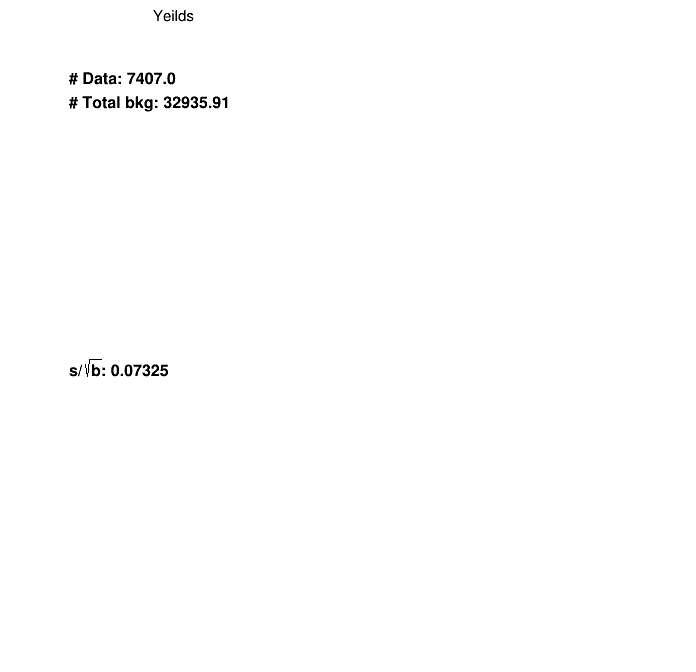

In [61]:
if DRAW_SR:
    region = "SR"

    with Pool() as p:
        p.starmap(wrapper_mp, list_variables) 
#     wrapper_mp('mass_pre', [45, 100, 1000, 'M_{ll} [GeV]'])

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)

array('f', [10.651510238647461, 12.057334899902344, 17.994773864746094, 293.2737121582031, 665.6618041992188, 6653.63916015625, 6752.201171875, 6607.94091796875, 6653.0595703125, 6665.35400390625, 201.58547973632812, 13.296531677246094])
test


Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230502pdf_17/Presel/ee17/SR/normblind_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230502pdf_17/Presel/ee17/SR/normblind_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_pre.pdf has been created
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230502pdf_17/Presel/ee17/SR/wotop/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230502pdf_17/Presel/ee17/SR/wotop/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_pre.pdf has been created
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 2023050

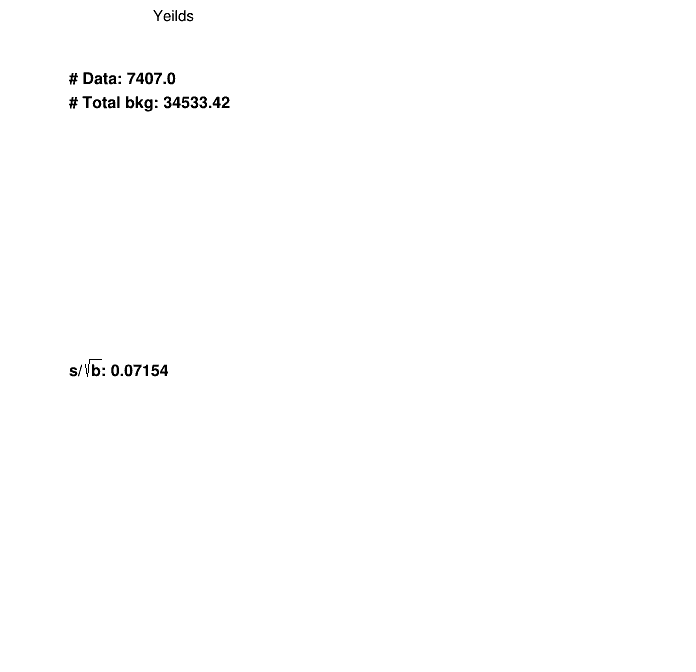

In [62]:
###### wotop ######
dic_variable={
    "PuppiMET_pre": [14, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
    "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
    "pt_trail_pre": [15, 40, 520, "p_{T}(l_{trail}) [GeV]"], 
}
os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region+"/wotop")

for variable, r in dic_variable.items():
    if not "Puppi" in variable:
        threshold = 0.3
    else:
        threshold = 0.5
    hist=HistStack(dic_df_raw, variable, "weight", r[0], r[1], r[2], r[3])  
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/normblind_"+query_str, blind_from=threshold)        
    hist=HistStack(dic_df_raw, variable, "wotop", r[0], r[1], r[2], r[3])  
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/wotop/norm_"+query_str, blind_from=threshold) 
hist.get_yeilds()
hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/wotop/pie_"+query_str)  

In [63]:
dic_df_raw["TT"]["trigSF_pre"]

0         0.987004
3         0.993395
26        0.996223
29        0.995788
32        0.996223
            ...   
132858    0.992209
132859    0.995576
132863    0.995576
132872    0.991613
132879    0.996223
Name: trigSF_pre, Length: 220575, dtype: float32

# Signal Acc x Eff x presel

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TROOT::Append>: Replacing existing TH1: h2d1 (Potential memory leak).
Info in <TCanvas::Print>: pdf file 20230502pdf_17/Presel/ee17/SR/sig_eff.pdf has been created


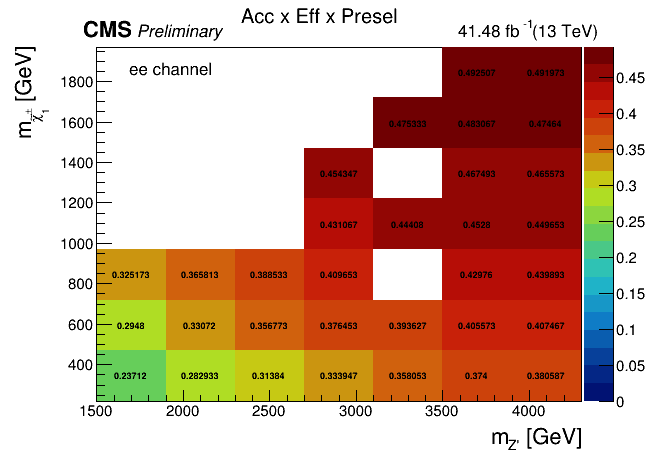

In [64]:
str_channel, str_lumi = HistStack.get_str_lumi_channel(ERA, ERA)

Zp_mass=[1700, 2100, 2500, 2900, 3300, 3700, 4100]
CH_mass=[345, 595, 845, 1095, 1345, 1595, 1845]
c1=rt.TCanvas("c1", "c1", 650, 500)
c1.SetLeftMargin(0.15)
c1.SetBottomMargin(0.15)
h2d1=rt.TH2D("h2d1", "", len(Zp_mass), Zp_mass[0]-200, Zp_mass[-1]+200, len(CH_mass), CH_mass[0]-125, CH_mass[-1]+125)
h2d1.SetTitle("Acc x Eff x Presel")

n_sig_in = 150000/4
if "em" in ERA:
    n_sig_in = 150000/2

for key in dic_df_raw:
    if not "Zp" in key:
        continue
    tmp=key.replace('_', '-')
    tmp=tmp.split('-')
    
    MZp=tmp[1]
    MCH=tmp[3]
    binx=Zp_mass.index(int(MZp))+1
    biny=CH_mass.index(int(MCH))+1
    h2d1.SetBinContent(binx, biny, dic_df_raw[key].shape[0]/(n_sig_in))
# # missing bin by hand
# h2d1.SetBinContent(5, 3, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000
# h2d1.SetBinContent(3, 4, 40000/(n_sig_in)) #mumu: 23500, #ee: 20000

# set_palette("rainbow",255)
rt.gStyle.SetOptStat(0)
rt.gStyle.SetPalette(55)

h2d1.Draw("colz text")
h2d1.SetYTitle("m_{#tilde#chi_{1}^{#pm}} [GeV]")
h2d1.SetXTitle("m_{Z'} [GeV]")
h2d1.GetYaxis().SetTitleSize(0.05)
h2d1.GetXaxis().SetTitleSize(0.05)
latex=rt.TLatex()
latex.DrawLatexNDC( 0.2,0.84, "#scale[0.8]{#font[42]{"+str_channel+" channel}}")

latex1=rt.TLatex()
latex1.DrawLatexNDC(0.71, 0.92, "#font[42]{#scale[0.8]{"+str_lumi+" fb^{-1}(13 TeV)}}");
latex1.DrawLatexNDC(0.13, 0.92, "#font[62]{CMS}#font[42]{#it{#scale[0.8]{ Preliminary}}}");
 
c1.Draw()
c1.SaveAs(DATE+"/Presel/"+ERA+"/"+region+"/sig_eff.pdf")

# MET side band

####################################################
####   (unweighted) #events after preselection  ####
####################################################
DY1000To1500 : 478
DY1500To2000 : 444
DY2000To3000 : 470
DY500To700 : 434
DY700To800 : 379
DY800To1000 : 417
Zp-1700_CH-345 : 1284
Zp-1700_CH-595 : 971
Zp-1700_CH-845 : 742
Zp-2100_CH-345 : 1181
Zp-2100_CH-595 : 991
Zp-2100_CH-845 : 770
Zp-2500_CH-345 : 1089
Zp-2500_CH-595 : 897
Zp-2500_CH-845 : 734
Zp-2900_CH-1095 : 500
Zp-2900_CH-1345 : 504
Zp-2900_CH-345 : 1026
Zp-2900_CH-595 : 806
Zp-2900_CH-845 : 631
Zp-3300_CH-1095 : 541
Zp-3300_CH-1595 : 353
Zp-3300_CH-345 : 996
Zp-3300_CH-595 : 777
Zp-3700_CH-1095 : 468
Zp-3700_CH-1345 : 388
Zp-3700_CH-1595 : 333
Zp-3700_CH-1845 : 301
Zp-3700_CH-345 : 872
Zp-3700_CH-595 : 717
Zp-3700_CH-845 : 569
Zp-4100_CH-1095 : 428
Zp-4100_CH-1345 : 348
Zp-4100_CH-1595 : 336
Zp-4100_CH-1845 : 302
Zp-4100_CH-345 : 808
Zp-4100_CH-595 : 652
Zp-4100_CH-845 : 595
TT : 119423
TThdampUp : 44688
TThdampDown : 

        0.        , 75.70314783, 48.68466978, 62.42155312, 51.05387995])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
{'puweightUp': array([3.03941561e+02, 2.70245998e+02, 1.22485270e+01, 1.08734757e+01,
       7.14172820e+00, 1.68067376e+00, 1.62916984e+00, 3.32514933e-01,
       1.12412895e+00, 1.05299094e-01, 8.58204373e-02, 4.52634612e-01,
       3.04415242e-02, 6.50313363e-01, 8.91045273e-03, 1.97649008e-02,
       0.00000000e+00, 3.69587576e-04, 0.00000000e+00, 5.18395073e-02,
       2.33035909e-03, 1.51314446e-03, 1.11086900e-03, 4.23615271e-04,
       2.35213973e-05, 1.28373820e-04, 3.40212897e-02, 6.19151319e-04,
       1.25199891e-05, 7.69487913e-05, 9.71671802e-05]), 'puweightDown': array([2.56630579e+01, 1.52459746e+02, 1.20980846e+01, 7.89239465e+00,
       6.60772934e+00,

       1.90928833e+00, 6.53425371e-02, 1.17631014e-01])}
here {'puweightUp': array([3.03941561e+02, 2.70245998e+02, 1.22485270e+01, 1.08734757e+01,
       7.14172820e+00, 1.68067376e+00, 1.62916984e+00, 3.32514933e-01,
       1.12412895e+00, 1.05299094e-01, 8.58204373e-02, 4.52634612e-01,
       3.04415242e-02, 6.50313363e-01, 8.91045273e-03, 1.97649008e-02,
       0.00000000e+00, 3.69587576e-04, 0.00000000e+00, 5.18395073e-02,
       2.33035909e-03, 1.51314446e-03, 1.11086900e-03, 4.23615271e-04,
       2.35213973e-05, 1.28373820e-04, 3.40212897e-02, 6.19151319e-04,
       1.25199891e-05, 7.69487913e-05, 9.71671802e-05]), 'puweightDown': array([2.56630579e+01, 1.52459746e+02, 1.20980846e+01, 7.89239465e+00,
       6.60772934e+00, 5.21465466e-01, 5.79589781e+00, 3.85195863e-02,
       2.65650148e+00, 7.97904524e-01, 1.01776780e-02, 5.79242428e-01,
       2.11492909e-03, 8.99671329e-01, 0.00000000e+00, 3.96090829e-03,
       6.22974206e-02, 6.35600126e-05, 3.77765177e-02, 6.92015772e-02

       1.90928833e+00, 6.53425371e-02, 1.17631014e-01])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
{'puweightUp': array([3.24198634e+01, 3.99126680e+01, 6.55194835e+02, 3.97098165e-02,
       2.46255015e+01, 5.42366185e+00, 2.40299984e-01, 2.99603350e-01,
       1.74004095e+00, 8.31830465e+00, 0.00000000e+00, 3.79830626e-02,
       0.00000000e+00, 2.33214527e-02, 1.04697349e-02, 1.57084883e-03,
       7.92706849e-04, 1.36919693e-04, 6.95242109e-03, 4.14111928e-04,
       3.34456730e-04, 1.03153330e-04, 1.10852767e-03, 1.11791007e-03,
       6.61328149e-04, 4.31434933e-07, 1.23682626e-03, 1.87362372e-05,
       7.50793385e-04, 2.66330906e-03]), 'puweightDown': array([7.80139449e+00, 4.35750405e+01, 2.11447320e+02, 1.17035852e+00,
       4.07102478e+00, 2.05641818e-01, 1.92431293e-01, 

       1.14513902e-02, 1.46437170e-01])}
here {'puweightUp': array([3.24198634e+01, 3.99126680e+01, 6.55194835e+02, 3.97098165e-02,
       2.46255015e+01, 5.42366185e+00, 2.40299984e-01, 2.99603350e-01,
       1.74004095e+00, 8.31830465e+00, 0.00000000e+00, 3.79830626e-02,
       0.00000000e+00, 2.33214527e-02, 1.04697349e-02, 1.57084883e-03,
       7.92706849e-04, 1.36919693e-04, 6.95242109e-03, 4.14111928e-04,
       3.34456730e-04, 1.03153330e-04, 1.10852767e-03, 1.11791007e-03,
       6.61328149e-04, 4.31434933e-07, 1.23682626e-03, 1.87362372e-05,
       7.50793385e-04, 2.66330906e-03]), 'puweightDown': array([7.80139449e+00, 4.35750405e+01, 2.11447320e+02, 1.17035852e+00,
       4.07102478e+00, 2.05641818e-01, 1.92431293e-01, 1.61130679e-02,
       1.56721414e+01, 3.12494767e+00, 6.17441244e-01, 5.13440383e-02,
       6.05631231e-02, 2.50647017e-03, 5.52358799e-05, 1.05866899e-03,
       8.12593148e-04, 2.18435022e-04, 5.17611201e-03, 3.34081947e-04,
       3.02802784e-04, 2.83458

       1.14513902e-02, 1.46437170e-01])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
array('f', [3.28082537651062, 3.48506236076355, 10.045527458190918, 176.9761199951172, 358.5100402832031, 3492.828369140625, 3505.271484375, 3521.14794921875, 3519.99755859375, 3485.335205078125, 486.8836364746094, 1.2218554019927979])
test


Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230502pdf_17/Presel/ee17/METSB/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_pt_lead_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230502pdf_17/Presel/ee17/METSB/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_pt_lead_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230502pdf_17/Presel/ee17/METSB/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80_PuppiMET_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230502pdf_17/Presel/ee17/METSB/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET

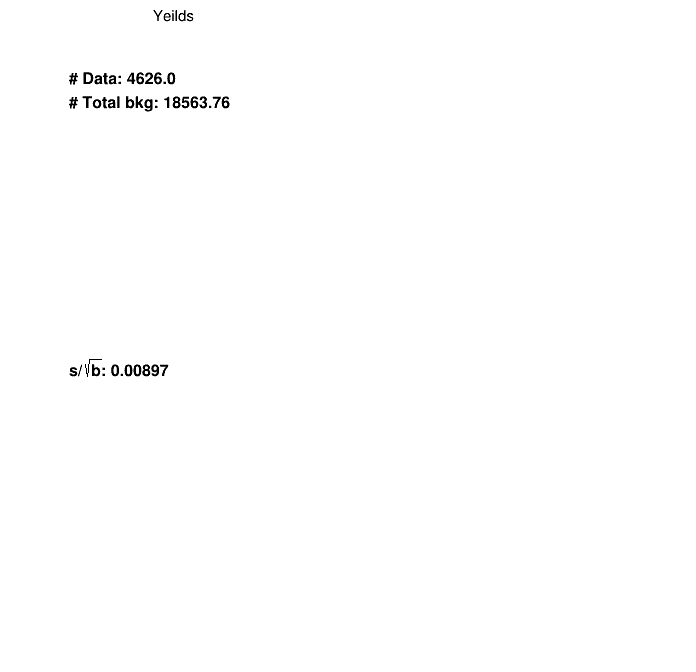

In [65]:
if RUN_SIDEBAND_MET:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
#         dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#         dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp    
#     nested_dic_df["scale_u"]=dic_df_scale_u_tmp
#     nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    dic_variable={
        "PuppiMET_pre": [20, 0, 100, "Puppi p_{T}^{miss} [GeV]"],    
#         "MET_pre": [40, 0, 400, "p_{T}^{miss} [GeV]"],    
#         "mass_pre": [30, 100, 700, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
#         "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
#         "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
#         "U_pre": [29, 0, 660, "U [GeV]"],
#         "JZB_pre": [29, 80, 660, "JZB"],
#         "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#         "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#         "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#         "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
    #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
    #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
    #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],      
    }
    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "METSB"
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)        

In [66]:
if DUMP_SIDEBAND_MET_PKL:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_METSB.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# Mass side band

In [67]:
if RUN_SIDEBAND_MASS and not "em" in ERA:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
#         dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#         dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp
#     nested_dic_df["scale_u"]=dic_df_scale_u_tmp
#     nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    
    dic_variable={
        "PuppiMET_pre": [28, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
        "mass_pre": [1,80, 100, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],     
    }

    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "MASSSB"
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "mass_pre", "weight", 1, 80,  100, "M_{ll} [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
    hist.get_yeilds()
    hist.create_root_file(file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")
    hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB") 
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)
    
    sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF"] 
#     sys_list = ["puweight", "l1prefiring", "effSF", "topSF"] 
    for s in sys_list:
        hist=HistStack(dic_df_raw, "mass_pre", 'weight'+s+'Up', 1, 80,  100, "M_{ll} [GeV]")
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
        hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")
        hist=HistStack(dic_df_raw, "mass_pre", 'weight'+s+'Down', 1, 80,  100, "M_{ll} [GeV]")
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
        hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")
    hist=HistStack(dic_df_met_u_tmp, "mass_pre", 'weightmetUp', 1, 80,  100, "M_{ll} [GeV]")
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
    hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB") 
    hist=HistStack(dic_df_met_d_tmp, "mass_pre", 'weightmetDown', 1, 80,  100, "M_{ll} [GeV]")
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/massSB_"+query_str) 
    hist.export_hist("Zp-2500_CH-345", file_name=DATE+"/Presel/"+ERA+"/"+region+"/shape_v1_massSB")      

####################################################
####   (unweighted) #events after preselection  ####
####################################################
DY1000To1500 : 0
DY1500To2000 : 0
DY2000To3000 : 0
DY500To700 : 0
DY700To800 : 0
DY800To1000 : 0
Zp-1700_CH-345 : 16
Zp-1700_CH-595 : 395
Zp-1700_CH-845 : 1064
Zp-2100_CH-345 : 11
Zp-2100_CH-595 : 173
Zp-2100_CH-845 : 547
Zp-2500_CH-345 : 4
Zp-2500_CH-595 : 64
Zp-2500_CH-845 : 317
Zp-2900_CH-1095 : 314
Zp-2900_CH-1345 : 425
Zp-2900_CH-345 : 3
Zp-2900_CH-595 : 32
Zp-2900_CH-845 : 174
Zp-3300_CH-1095 : 225
Zp-3300_CH-1595 : 377
Zp-3300_CH-345 : 3
Zp-3300_CH-595 : 18
Zp-3700_CH-1095 : 143
Zp-3700_CH-1345 : 206
Zp-3700_CH-1595 : 284
Zp-3700_CH-1845 : 290
Zp-3700_CH-345 : 6
Zp-3700_CH-595 : 10
Zp-3700_CH-845 : 73
Zp-4100_CH-1095 : 111
Zp-4100_CH-1345 : 187
Zp-4100_CH-1595 : 198
Zp-4100_CH-1845 : 209
Zp-4100_CH-345 : 1
Zp-4100_CH-595 : 8
Zp-4100_CH-845 : 64
TT : 10223
TThdampUp : 4211
TThdampDown : 3528
TTUp : 4081
TTDown : 3771
TTSemi

       2.67014768e-01, 8.95414220e-03, 2.10116837e+00])}
here{'puweightUp': array([6.26484452e+01, 1.19955875e+02, 0.00000000e+00, 4.03620523e+00,
       1.67766607e-01, 1.18982451e+01, 5.02667039e+00, 1.39833223e+00,
       5.60871642e-01, 3.39571917e-01, 4.56542867e-04, 2.93963601e-01,
       1.86367661e-05, 1.49222104e-02, 1.53551253e-06, 0.00000000e+00,
       7.49394563e-07, 2.86857929e-08, 0.00000000e+00, 7.62530508e-08,
       4.16026066e-07, 0.00000000e+00, 0.00000000e+00, 2.79161988e-06,
       9.43754773e-09, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00]), 'puweightDown': array([1.06981913e+02, 1.57384550e+02, 1.54067121e+01, 2.01604679e+01,
       5.51939844e-01, 3.61395093e+01, 2.00654495e+01, 2.04344496e+00,
       3.15954209e-01, 4.16409431e-01, 7.77032749e-03, 2.30824219e-01,
       4.54863670e-05, 0.00000000e+00, 0.00000000e+00, 5.99597762e-07,
       2.48165855e-07, 5.26347794e-10, 0.00000000e+00, 6.08495248e-08,
       2.418217

       0.00000000e+00, 0.00000000e+00])} 
here {'puweightUp': array([5.36279046e+01, 9.58719665e+01, 1.22741394e-02, 3.28225905e+01,
       1.86375027e+00, 1.63180955e+00, 4.68024187e+01, 1.48750890e+00,
       0.00000000e+00, 0.00000000e+00, 4.49504162e-01, 3.11170591e-01,
       9.15069786e-02, 2.80016551e-04, 9.07309800e-01, 1.09854059e-02,
       3.47744132e+00, 9.01175589e-01, 2.74771041e-02, 2.18644550e-01,
       1.91199175e-01, 8.75339624e-03, 2.44805449e-01, 2.96154528e-01,
       1.39453492e-05, 1.09649413e-01, 3.92788088e-05, 1.08405615e-05,
       7.38198176e-02, 3.94718150e-06, 2.30234167e-03]), 'puweightDown': array([1.30389701e+02, 6.18994793e+01, 2.66929752e+01, 7.27043919e+01,
       1.03475631e+01, 3.18630834e+00, 1.94463931e+01, 8.46926407e+00,
       2.22354723e+00, 1.49810851e+00, 1.34655167e-01, 1.51460875e+00,
       1.52847408e-02, 2.68318470e-01, 1.42657904e-01, 2.08482946e-01,
       3.02043582e+00, 8.12680687e-01, 8.81223099e-02, 2.87602339e-02,
       7.8200

       2.67014768e-01, 8.95414220e-03, 2.10116837e+00])}
{'puweightUp': array([6.26484452e+01, 1.19955875e+02, 0.00000000e+00, 4.03620523e+00,
       1.67766607e-01, 1.18982451e+01, 5.02667039e+00, 1.39833223e+00,
       5.60871642e-01, 3.39571917e-01, 4.56542867e-04, 2.93963601e-01,
       1.86367661e-05, 1.49222104e-02, 1.53551253e-06, 0.00000000e+00,
       7.49394563e-07, 2.86857929e-08, 0.00000000e+00, 7.62530508e-08,
       4.16026066e-07, 0.00000000e+00, 0.00000000e+00, 2.79161988e-06,
       9.43754773e-09, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
       0.00000000e+00, 0.00000000e+00]), 'puweightDown': array([1.06981913e+02, 1.57384550e+02, 1.54067121e+01, 2.01604679e+01,
       5.51939844e-01, 3.61395093e+01, 2.00654495e+01, 2.04344496e+00,
       3.15954209e-01, 4.16409431e-01, 7.77032749e-03, 2.30824219e-01,
       4.54863670e-05, 0.00000000e+00, 0.00000000e+00, 5.99597762e-07,
       2.48165855e-07, 5.26347794e-10, 0.00000000e+00, 6.08495248e-08,
       2.41821762e-

       0.00000000e+00, 0.00000000e+00])}
{'puweightUp': array([115.83287054]), 'puweightDown': array([641.18497176]), 'l1prefiringUp': array([189.06494593]), 'l1prefiringDown': array([183.96026649]), 'effSFUp': array([2282.38680226]), 'effSFDown': array([2167.08698661]), 'topSFUp': array([33.07099562]), 'topSFDown': array([0.]), 'metUp': array([44663.87679627]), 'metDown': array([7152.34790693]), 'trigSFUp': array([28.64748855]), 'trigSFDown': array([34.06840349]), 'hdampUp': array([298.65542813]), 'hdampDown': array([186.36043013]), 'PSUp': array([3.26903165]), 'PSDown': array([7.77026628]), 'sum_up': array([218.20816749]), 'sum_down': array([101.84684203])}
here {'puweightUp': array([115.83287054]), 'puweightDown': array([641.18497176]), 'l1prefiringUp': array([189.06494593]), 'l1prefiringDown': array([183.96026649]), 'effSFUp': array([2282.38680226]), 'effSFDown': array([2167.08698661]), 'topSFUp': array([33.07099562]), 'topSFDown': array([0.]), 'metUp': array([44663.87679627]), 'me

       5.09868381e-02, 1.39298996e-01, 2.20341791e-01, 9.16568870e-02])}
here {'puweightUp': array([1.74826810e+02, 2.07790960e+00, 0.00000000e+00, 2.93182631e+00,
       0.00000000e+00, 2.34187862e+00, 3.92954547e-01, 1.94584297e-01,
       6.41368313e-01, 1.73862664e-01, 1.27164879e-02, 7.25114862e-02,
       9.20792674e-04, 2.21707048e-04, 4.16842759e-07, 5.07687522e-04,
       4.46197638e-03, 1.14595959e-03, 2.93837196e-04, 1.02200532e-03,
       1.03636421e-03, 4.79811708e-04, 2.03216440e-05, 3.95682429e-05,
       4.33056354e-05, 1.57701256e-04, 1.26079346e-05, 2.20024546e-04]), 'puweightDown': array([5.87838253e+02, 1.11688854e+00, 5.93424182e+00, 9.65309586e+00,
       4.26546889e-01, 3.87870124e+00, 5.35541306e-01, 6.81993119e-01,
       2.48991080e-01, 6.97697188e-02, 1.93747050e-02, 9.83610049e-02,
       2.53862456e-02, 2.56462946e-03, 3.25045315e-04, 7.60231481e-05,
       7.45362140e-03, 1.19553449e-03, 1.33952943e-03, 1.27331647e-03,
       8.89804016e-04, 3.54828610e-04

       5.09868381e-02, 1.39298996e-01, 2.20341791e-01, 9.16568870e-02])}
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_uppuweightUp

sum_downpuweightDown

['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']l1prefiringUp

l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 'l1prefiring', 'effSF', 'topSF', 'met', 'trigSF', 'hdamp', 'PS']
puweightUp
puweightDown
l1prefiringUp
l1prefiringDown
effSFUp
effSFDown
topSFUp
topSFDown
metUp
metDown
trigSFUp
trigSFDown
hdampUp
hdampDown
PSUp
PSDown
sum_up
sum_down
['puweight', 

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Info in <TCanvas::Print>: pdf file 20230502pdf_17/Presel/ee17/MASSSB/sys/norm_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_trail_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230502pdf_17/Presel/ee17/MASSSB/sys/norm_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_trail_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230502pdf_17/Presel/ee17/MASSSB/sys/norm_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230502pdf_17/Presel/ee17/MASSSB/sys/norm_mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>

In [68]:
if DUMP_SIDEBAND_MASS_PKL and not "em" in ERA:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_MASS.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

# PT side band

In [ ]:
if RUN_SIDEBAND_PT:
    dic_df_raw={}
    dic_df_met_u_tmp = {}
    dic_df_met_d_tmp = {}
    dic_df_scale_u_tmp = {}
    dic_df_scale_d_tmp = {}
    # query_str="mass_pre<100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre<40 and PuppiMET_pre>100"
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre<100 and PuppiMET_pre>80"
    # query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and MET_pre>80"
    # query_str="mass_pre>60"

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)
        dic_df_met_u_tmp[key]=dic_df_met_u[key].query(query_str)
        dic_df_met_d_tmp[key]=dic_df_met_d[key].query(query_str)     
#         dic_df_scale_u_tmp[key]=dic_df_scale_u[key].query(query_str)
#         dic_df_scale_d_tmp[key]=dic_df_scale_d[key].query(query_str) 
        print(key, ":", dic_df_raw[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_u[key].shape[0])
    #     print("num of", key, ":", dic_df_jes_d[key].shape[0])
    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u_tmp
    nested_dic_df["met_d"]=dic_df_met_d_tmp    
#     nested_dic_df["scale_u"]=dic_df_scale_u_tmp
#     nested_dic_df["scale_d"]=dic_df_scale_d_tmp
    dic_variable={
        "PuppiMET_pre": [14, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
#         "MET_pre": [40, 0, 400, "p_{T}^{miss} [GeV]"],    
        "mass_pre": [22, 100, 1000, "M_{ll} [GeV]"],
        "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
        "pt_trail_pre": [4, 0, 40, "p_{T}(l_{trail}) [GeV]"],
#         "Zpt_pre": [25, 0, 500, "p_{T}(ll) [GeV]"],
#         "MT_pre": [27, 0, 550, "M_{T} [GeV]"],
#         "MT2_pre": [17, 0, 350, "M_{T2} [GeV]"],
#         "U_pre": [14, 0, 660, "U [GeV]"],
#         "JZB_pre": [14, 80, 660, "JZB"],
#         "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#         "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#         "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#         "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
#     #     "MC1C1_pre": [36, 180, 900, "MC1C1 [GeV]"], 
#     #     "H3PP_pre": [41, 80, 900, "H3PP [GeV]"], 
#     #     "H3TPP_pre": [40, 0, 800, "H3TPP [GeV]"], 
#         "eta_lead_pre": [15, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [15, -3, 3, "#eta(l_{trail})"],
# #         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
# #         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [20, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"],      
    }
    list_variables = [(key, dic_variable[key]) for key in dic_variable]
    
    region = "PTSB"
    os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+region)
    
    sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "hdamp", "PS"]
    
    with Pool() as p:
        p.starmap(wrapper_mp, list_variables)    

    # for pie chart
    hist=HistStack(dic_df_raw, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/"+region+"/pie_"+query_str)        

####################################################
####   (unweighted) #events after preselection  ####
####################################################
DY1000To1500 : 50
DY1500To2000 : 38
DY2000To3000 : 29
DY500To700 : 56
DY700To800 : 53
DY800To1000 : 41
Zp-1700_CH-345 : 1118
Zp-1700_CH-595 : 1012
Zp-1700_CH-845 : 834
Zp-2100_CH-345 : 1122
Zp-2100_CH-595 : 994
Zp-2100_CH-845 : 794
Zp-2500_CH-345 : 1030
Zp-2500_CH-595 : 955
Zp-2500_CH-845 : 836
Zp-2900_CH-1095 : 651
Zp-2900_CH-1345 : 553
Zp-2900_CH-345 : 988
Zp-2900_CH-595 : 922
Zp-2900_CH-845 : 788
Zp-3300_CH-1095 : 619
Zp-3300_CH-1595 : 431
Zp-3300_CH-345 : 857
Zp-3300_CH-595 : 900
Zp-3700_CH-1095 : 608
Zp-3700_CH-1345 : 452
Zp-3700_CH-1595 : 402
Zp-3700_CH-1845 : 346
Zp-3700_CH-345 : 818
Zp-3700_CH-595 : 753
Zp-3700_CH-845 : 708
Zp-4100_CH-1095 : 555
Zp-4100_CH-1345 : 417
Zp-4100_CH-1595 : 386
Zp-4100_CH-1845 : 319
Zp-4100_CH-345 : 722
Zp-4100_CH-595 : 675
Zp-4100_CH-845 : 625
TT : 75509
TThdampUp : 28583
TThdampDown : 27768
T

Process ForkPoolWorker-204:
Process ForkPoolWorker-197:
Process ForkPoolWorker-217:
Process ForkPoolWorker-208:
Process ForkPoolWorker-223:
Process ForkPoolWorker-207:
Process ForkPoolWorker-221:
Process ForkPoolWorker-222:
Process ForkPoolWorker-198:
Process ForkPoolWorker-224:
Process ForkPoolWorker-201:
Process ForkPoolWorker-200:
Process ForkPoolWorker-211:
Process ForkPoolWorker-213:
Process ForkPoolWorker-199:
Process ForkPoolWorker-214:
Process ForkPoolWorker-210:
Process ForkPoolWorker-220:
Process ForkPoolWorker-218:
Process ForkPoolWorker-209:
Process ForkPoolWorker-205:
Process ForkPoolWorker-203:
Process ForkPoolWorker-206:
Process ForkPoolWorker-219:
Process ForkPoolWorker-216:
Process ForkPoolWorker-215:
Process ForkPoolWorker-212:
Process ForkPoolWorker-202:
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-g

  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/multiprocessing/process.py", line 315, in _bootstrap
    self.run()
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/multiprocessing/queues.py", line 365, in get
    with self._rlock:
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/multiprocessing/pool.py", line 114, in worker
    task = get()
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/multiprocessing/process.py", line 315, in _bootstrap
    self.run()
  File "/cvmfs/sft.cern.ch/lcg/releases/Py

  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/multiprocessing/pool.py", line 51, in starmapstar
    return list(itertools.starmap(args[0], args[1]))
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/multiprocessing/queues.py", line 365, in get
    with self._rlock:
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/multiprocessing/synchronize.py", line 95, in __enter__
    return self._semlock.__enter__()
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc

  File "/tmp/ipykernel_13012/694088336.py", line 31, in draw_with_systematics
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systDown_"+s+query_str)
  File "/tmp/ipykernel_13012/465979302.py", line 14, in wrapper_mp
    dic_sys_sqr = draw_with_systematics(dic_df_raw, nested_dic_df, sys_list, variable, dic_variable[variable], region)
  File "/tmp/ipykernel_13012/694088336.py", line 31, in draw_with_systematics
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systDown_"+s+query_str)
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/multiprocessing/pool.py", line 51, in starmapstar
    return list(itertools.starmap(args[0], args[1]))
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/multiprocessing/pool.py", line 125, in worker
    result = (True, func(*args, **kwds))
  File "/tmp/ipykernel_13012/465979302

...

  File "/eos/home-i02/h/hkwon/SWAN_projects/Zpeak/./Utils/Plotter.py", line 30, in get_dic_hist
    h.Fill(v, df[self.weight].iat[i])
  File "/cvmfs/sft.cern.ch/lcg/views/LCG_102b_swan/x86_64-centos7-gcc11-opt/lib/python3.9/site-packages/pandas/core/frame.py", line 2996, in __getitem__
    return self._get_item_cache(key)
  File "pandas/_libs/lib.pyx", line 1038, in pandas._libs.lib.c_is_list_like
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/abc.py", line 117, in __instancecheck__
    def __instancecheck__(cls, instance):
KeyboardInterrupt
  File "/cvmfs/sft.cern.ch/lcg/views/LCG_102b_swan/x86_64-centos7-gcc11-opt/lib/python3.9/site-packages/pandas/core/generic.py", line 3786, in _get_item_cache
    res = cache.get(item)
KeyboardInterrupt
ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this in

Traceback (most recent call last):
  File "/tmp/ipykernel_13012/582958798.py", line 63, in <module>
    p.starmap(wrapper_mp, list_variables)
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/multiprocessing/pool.py", line 372, in starmap
    return self._map_async(func, iterable, starmapstar, chunksize).get()
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/multiprocessing/pool.py", line 765, in get
    self.wait(timeout)
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/multiprocessing/pool.py", line 762, in wait
    self._event.wait(timeout)
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/threading.py", line 574, in wait
    signaled = self._cond.wait(timeout)
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/threading.py", line 312, in wa

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/tmp/ipykernel_13012/582958798.py", line 63, in <module>
    p.starmap(wrapper_mp, list_variables)
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/multiprocessing/pool.py", line 372, in starmap
    return self._map_async(func, iterable, starmapstar, chunksize).get()
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/multiprocessing/pool.py", line 765, in get
    self.wait(timeout)
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/multiprocessing/pool.py", line 762, in wait
    self._event.wait(timeout)
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/threading.py", line 574, in wait
    signaled = self._cond.wait(timeout)
  File "/cvmfs/sft.cern.ch/lcg/releases/Python/3.9.12-9a1bc/x86_64-centos7-gcc11-opt/lib/python3.9/threading.py", line 312, in wa

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas::Constructor>: Deleting canvas with same name: c1
Warning in <TCanvas:

In [68]:
if DUMP_SIDEBAND_PT_PKL:
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_PT.pkl", "wb") as f:
        pickle.dump(nested_dic_df, f)

ERROR! Session/line number was not unique in database. History logging moved to new session 12


ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Traceback (most recent call last):
  File "/cvmfs/sft.cern.ch/lcg/views/LCG_102b_swan/x86_64-centos7-gcc11-opt/lib/python3.9/site-packages/IPython/core/interactiveshell.py", line 3441, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/tmp/ipykernel_13012/1604320501.py", line 2, in <module>
    with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_PT.pkl", "wb") as f:
KeyboardInterrupt

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/cvmfs/sft.cern.ch/lcg/views/LCG_102b_swan/x86_64-centos7-gcc11-opt/lib/python3.9/site-packages/IPython/core/interactiveshell.py", line 2061, in showtraceback
    stb = value._render_traceback_()
AttributeError: 'KeyboardInterrupt' object has no attribute '_render_traceback_'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/cvmfs/sft.cern.ch/lcg/views/LCG_102b_swan/x86_64-centos7-gcc11-opt/lib/python3.9/site-pa

TypeError: object of type 'NoneType' has no len()

# b tag selection

In [ ]:
if RUN_BTAG:
    dic_variable={
        "MET_pre": [25, 0, 500, "p_{T}^{miss} [GeV]"],    
#         "PuppiMET_pre": [50, 0, 500, "Puppi p_{T}^{miss} [GeV]"],    
#         "mass_pre": [30, 100, 700, "M_{ll} [GeV]"],
        "pt_lead_pre": [31, 80,  660, "p_{T}(l_{lead}) [GeV]"],
#         "pt_trail_pre": [30, 40, 520, "p_{T}(l_{trail}) [GeV]"],
#         "Zpt_pre": [50, 0, 500, "p_{T}(ll) [GeV]"],
        "MT_pre": [55, 0, 550, "M_{T} [GeV]"],
#         "MT2_pre": [35, 0, 350, "M_{T2} [GeV]"],
#         "U_pre": [29, 0, 660, "U [GeV]"],
#         "JZB_pre": [29, 80, 660, "JZB"],
#         "dPhill_pre": [17, 0, 3.4, "#Delta#phi(l,l)"],
#         "dPhilMET_pre": [17, 0, 3.4, "#Delta#phi(l,p_{T}^{miss})"],
#         "dRll_pre": [30, 0, 6, "#DeltaR(l,l)"],
#         "dPhillMET_pre": [17, 0, 3.4, "#Delta#phi(ll,p_{T}^{miss})"],
#         "eta_lead_pre": [30, -3, 3, "#eta(l_{lead})"],
#         "eta_trail_pre": [30, -3, 3, "#eta(l_{trail})"],
#         "phi_lead_pre": [40, -4, 4, "#phi(l_{lead})"],
#         "phi_trail_pre": [40, -4, 4, "#phi(l_{trail})"], 
#         "PuppiMET_phi_pre": [40, -4, 4, "Puppi p_{T}^{miss} #phi(l_{trail})"], 
        "nbjetflav_pre": [10, 0, 10, "N bjetflav"], 
#         "nbjet_pre": [10, 0, 10, "N bjet"], 
        "njet_pre": [10, 0, 10, "N jet"], 
#         "njet_l_pre": [9, 1, 10, "N  l jet"],     
#         "njet_c_pre": [9, 1, 10, "N  c jet"],     
#         "njet_b_pre": [9, 1, 10, "N  b jet"],    
#         "btagSF0_pre": [40, 0.9, 1.3, "B SF"],    
    }
    
#     base_line = "mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>80 and PuppiMET_pre>150 and MT_pre>130"
    base_line = "mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    dic_df_raw={}
#     query_str="mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100 and njet_pre==1" #temp!
#     query_str=base_line+" and nbjetflav_pre==0" #temp!
    query_str=base_line #temp!

    print("####################################################")
    print("####   (unweighted) #events after preselection  ####")
    print("####################################################")
    for key in dic_df:  
        dic_df_raw[key]=dic_df[key].query(query_str)  
        print(key, ":", dic_df_raw[key].shape[0])

    nested_dic_df={}
    nested_dic_df["raw"]=dic_df_raw
    nested_dic_df["met_u"]=dic_df_met_u
    nested_dic_df["met_d"]=dic_df_met_d
        
    sys_list = ["weight", "wobsf", "wotop"]
    for sys_key in sys_list:
        for variable, r in dic_variable.items():
            os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/Beq0/"+sys_key)
            hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
            c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/Beq0/"+sys_key+"/preselv1_"+query_str) 
    
#     hist=HistStack(dic_df_raw, "btagSF0_pre", "genweight_pre", 40, 0.9, 1.3, "B SF")            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/NONBTAG/"+sys_key+"/genweight_pre_preselv1_"+query_str, is_dnn=False) 

        #simply from last instance
        print(hist.get_yeilds())
        hist.draw_pie(file_name=DATE+"/Presel/"+ERA+"/Beq0/"+sys_key+"/pie_"+query_str)
        print(hist.nbin)    
    
#     with open(DATE+"/Presel/"+ERA+"/"+"nested_dic_df_Beq0.pkl", "wb") as f:
#         pickle.dump(nested_dic_df, f)

# Export variables

In [ ]:
if EXPORT_VARIABLE:
    # draw
    # get plot configuration
    dic_variable={
    #     "pt_trail_pre": [8, 40, 300, "p_{T}(l_{trail}) [GeV]"],
    #     "MT2_pre": [8, 0, 160, "M_{T2} [GeV]"],
        "H3PP_pre": [19, 95, 900, "H3PP [GeV]"],     
    }
    sys_src={
        "presel":["effSF_pre", "l1prefiring_pre", "puweight_pre"]
    #     "presel":["effSF_pre", "l1prefiring_pre", "puweight_pre", "topSF_pre"]
    }
    # sys_src=[]
    for key in dic_df_raw:
        if "Zp" in key:
            for variable, r in dic_variable.items():
                hist=HistStack(dic_df_raw, variable, sys_src, "presel", r[0], r[1], r[2], r[3])            
                c1=hist.draw_hist(key, ERA, ERA+"_exportdev"+query_str, True) 
                hist.create_root_file(key, variable, channel)
                hist.export_hist(key, variable, channel, "") 

    #simply from last instance
    print(hist.get_yeilds())
    hist.draw_pie()
    print(hist.nbin)
